In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Concise Implementation

In that section we wrote every part of linear regression
ourselves: the parameters and their initialization, the forward pass, the
squared loss, and the update of minibatch stochastic gradient descent.
Writing them out showed what each part computes, and we could check every
line against the formulas of that section. That model had
two weights and a bias, and the models of later chapters are far larger.
The image classifier ResNet-50 of that section, for instance, has
25.6 million parameters in 161 tensors, and it is trained with update rules
that keep a running average of past gradients for every parameter. Writing
and testing all of this by hand for every new model would take most of our
effort, and a mistake in any part rarely raises an error. The model still
trains, only less well. We need parts that are written and tested once, for
models of any size.

Deep learning frameworks such as MXNet [@Chen.Li.Li.ea.2015], JAX
[@Frostig.Johnson.Leary.2018] with its libraries Flax and Optax,
PyTorch [@Paszke.Gross.Massa.ea.2019], and TensorFlow
[@Abadi.Barham.Chen.ea.2016] therefore provide these parts ready-made.
Their layers, losses, and optimizers are tested by many users and run on
code tuned for each kind of hardware, and one loss or optimizer can be
swapped for another by changing a line. This section trains the same model
on the same synthetic data with framework parts only. A fully connected
layer holds the weights
and the bias and computes the predictions, a built-in loss computes the
squared error, and an optimizer object applies the update. The `Trainer`
of that section runs unchanged, because it calls only the methods
that every `Module` has. One difference needs care: the framework loss is
twice ours, which doubles the step that a given learning rate takes.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

## The Fully Connected Layer

Linear regression is a network with a single layer: every input feature is
connected to the one output, which computes $\mathbf{w}^\top \mathbf{x} + b$
(the figure). A layer in which every input is connected to
every output is called fully connected, or dense. For a minibatch with
design matrix $\mathbf{X}$ it computes the predictions
$\mathbf{X}\mathbf{w} + b$ that the `forward` method of our scratch model
wrote out. The layer creates and stores its own parameters. We choose only
the number of outputs, here 1, and how the parameters are initialized. As in
the scratch model, the weights are drawn from a normal distribution with
mean 0 and standard deviation 0.01, and the bias starts at 0.

In Keras the fully connected layer is `tf.keras.layers.Dense(1)`. Keras
takes the number of inputs from the first input that the layer receives and
creates the weights then, drawing them from the `kernel_initializer`. The
bias starts at zero by default.

In [2]:
class LinearRegression(d2l.Module):
    """Linear regression built from framework components."""
    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        init = tf.initializers.RandomNormal(stddev=0.01)
        self.net = tf.keras.layers.Dense(1, kernel_initializer=init)

The model needs no `forward` method of its own. It inherits the `forward`
of `Module` (that section), which passes its input to
`self.net`, here the layer.

## The Loss Function

Our scratch loss was half the squared error, averaged over the minibatch
$\mathcal{B}$. Most frameworks provide the *mean squared error* instead,

$$\frac{1}{|\mathcal{B}|}\sum_{i \in \mathcal{B}} \left(\hat{y}^{(i)} - y^{(i)}\right)^2,$$

which has no factor $\frac{1}{2}$. It is the usual measure of prediction
quality in regression: its square root is the typical size of an error, in
the units of the label. Our loss and the framework loss have the
same minimizer, but the framework loss and its gradient are twice ours. This
factor of 2 returns when we choose the learning rate.

`tf.keras.losses.MeanSquaredError` computes the mean squared error over the
minibatch. Keras losses take the label first and the prediction second, and
they bring both to the same shape before subtracting, so labels of shape
$(32,)$ cannot be broadcast against predictions of shape $(32, 1)$ into a
$32 \times 32$ matrix of differences.

In [3]:
@d2l.add_to_class(LinearRegression)
def loss(self, y_hat, y):
    fn = tf.keras.losses.MeanSquaredError()
    return fn(y, y_hat)

## The Optimizer

The optimizer replaces our `SGD` class. It receives the parameters and the
learning rate $\eta$, and at each step it subtracts $\eta$ times the
gradient of the minibatch loss from each parameter, the update we wrote by
hand. The optimizer finds the parameters through the layers of the model,
so a model with more layers needs no change here, and replacing minibatch
SGD by another update rule changes only this one line.

`tf.keras.optimizers.SGD` takes the learning rate. The parameters arrive at
each step together with their gradients, through `apply_gradients`, which
our trainer calls with the model's `trainable_variables`. The module
`tf.keras.optimizers` provides the other common update rules with the same
interface.

In [4]:
@d2l.add_to_class(LinearRegression)
def configure_optimizers(self):
    return tf.keras.optimizers.SGD(self.lr)

## Training

We train on the synthetic data of
that section: 1,000 training and 1,000
validation examples whose two features are drawn from a standard normal
distribution and whose labels are
$y = \mathbf{x}^\top \mathbf{w}^* + b^* + \epsilon$, with
$\mathbf{w}^* = (2, -3.4)$, $b^* = 4.2$, and noise $\epsilon$ of standard
deviation $\sigma = 0.01$. The data module serves the training examples in
minibatches of 32.

The learning rate needs one adjustment. Multiplying a loss by a constant $c$
multiplies its gradient by $c$, so SGD on the loss $cL$ with learning rate
$\eta$ takes the same steps as SGD on $L$ with learning rate $c\eta$
(that section). The framework loss is
twice our scratch loss, so the learning rate 0.015 reproduces the steps
that the scratch model took with 0.03. From the same initial parameters and
on the same minibatches, the two models compute the same updates. With 0.03
the concise model would take the steps of the scratch model at 0.06. On this
problem training would still converge, but it would no longer repeat the
computation of the scratch model.


We also put the trainer's plot, `trainer.board`, on a logarithmic scale, so
that the loss stays visible after it has fallen by several orders of
magnitude.

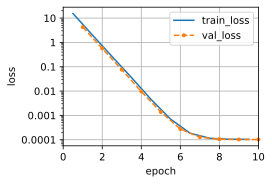

In [5]:
data = d2l.SyntheticRegressionData(w=d2l.tensor([2, -3.4]), b=4.2)
model = LinearRegression(lr=0.015)
trainer = d2l.Trainer(max_epochs=10)
trainer.board.yscale = 'log'
trainer.fit(model, data)

The plot shows the mean training loss of each epoch and the validation loss
after each epoch. Both curves fall along a straight line, by a factor of
about 7 per epoch, and level off near $10^{-4}$ after about eight epochs.
This is the behavior of the scratch model with every loss doubled.

In that section each step of the scratch model at
$\eta = 0.03$ multiplied the error of the parameters by $1 - \eta = 0.97$
on average, which compounds to a factor of about 7 per epoch in the loss.
The framework gradient is twice as large and the learning rate half as
large, so each step multiplies the error by the same factor,
$1 - 2\eta = 0.97$. The floor is
the loss of the true parameters, which leave the noise $\epsilon$
unexplained. For the mean squared error that loss is the noise variance
$\sigma^2 = 10^{-4}$, twice the floor $\sigma^2/2$ of the scratch loss.
The trainer keeps the numbers behind the plot in `trainer.history`, a
dictionary of per-epoch lists.

In [6]:
print(f"validation loss: {trainer.history['val_loss'][-1]:.2e}")

validation loss: 1.02e-04


The final validation loss lies within about 15% of $\sigma^2 = 10^{-4}$.

Since we generated the data, we can also compare the learned parameters with
$\mathbf{w}^*$ and $b^*$. The scratch model kept its parameters as `self.w`
and `self.b`. Here they belong to the layer, and `get_w_b` reads them out of
`net`.

`Dense` stores its weight, the `kernel`, as a $d \times 1$ column, so the
comparison below reshapes it to the shape of $\mathbf{w}^*$.

In [7]:
@d2l.add_to_class(LinearRegression)
def get_w_b(self):
    return self.net.kernel, self.net.bias

In [8]:
w, b = model.get_w_b()
w_error = d2l.numpy(d2l.reshape(w, data.w.shape) - data.w)
b_error = d2l.numpy(b - data.b)
print('error in w:', ', '.join(f'{e:.1e}' for e in w_error))
print('error in b:', ', '.join(f'{e:.1e}' for e in b_error))

error in w: -3.5e-04, -9.7e-05
error in b: -1.9e-04


The parameter errors $\hat{\mathbf{w}} - \mathbf{w}^*$ and $\hat{b} - b^*$
are typically a few times $10^{-4}$ and rarely exceed $10^{-3}$, as for the
scratch model. Errors of this size are expected: even the exact
least-squares solution misses each parameter by about
$\sigma/\sqrt{n} = 0.01/\sqrt{1000} \approx 3 \times 10^{-4}$, the
standard error of an average of $n = 1{,}000$ noisy terms. And as in the
scratch model, the bias, which starts 4.2 below $b^*$, is still about
$4.2 \times 0.97^{320} \approx 2.5 \times 10^{-4}$ short of it after the
320 steps of ten epochs.

We can now assemble a model from framework parts and train it with the
loop of the previous sections. The only adjustment was the learning rate,
which we scaled with the loss. The rest of the book builds its models the
same way, from the layers, losses, and optimizers of the framework, and
writes a part by hand only to show how it works or when the framework does
not provide it. Here we judged the trained model by its distance from
parameters that we chose ourselves. With real data the true parameters are
unknown, and what matters is how well a model predicts examples it has not
seen. that section takes up that question.

## Summary

Deep learning frameworks provide tested and fast versions of the parts we
wrote by hand for linear regression. A fully connected layer holds the
weights and the bias and computes the predictions, a loss function computes
the mean squared error, and an optimizer applies the SGD update to every
parameter of the model. Replacing each hand-written part by its framework
counterpart leaves `Module`, `DataModule`, and `Trainer` unchanged. The
framework loss omits the factor $\frac{1}{2}$ of our squared loss, so its
gradient is twice ours, and the learning rate 0.015 reproduces the steps of
the scratch model at 0.03. The trained model recovers $\mathbf{w}^*$ and
$b^*$ to within a few times $10^{-4}$, rarely more than $10^{-3}$, close to
the estimation error of least squares on 1,000 noisy examples, and its
validation loss
levels off at the noise variance $\sigma^2 = 10^{-4}$. Writing a part by
hand remains the way to understand it, and the way to build one that the
framework lacks.

## Exercises

1. [code] **Loss scaling.** The framework loss in `LinearRegression.loss`
   is twice the loss of `LinearRegressionScratch`.
    1. For one minibatch $\mathcal{B}$ of `SyntheticRegressionData`,
       compute the gradient of `LinearRegression.loss` with respect to the
       weights by automatic differentiation, and compare it entry by entry
       with the formula
       $\frac{2}{|\mathcal{B}|}\sum_{i \in \mathcal{B}} \mathbf{x}^{(i)}\left(\mathbf{w}^\top \mathbf{x}^{(i)} + b - y^{(i)}\right)$
       at the same parameters.
    1. Give `LinearRegression` and `LinearRegressionScratch` the same
       initial parameters and the same minibatches, for example by setting
       `batch_size` to `num_train` so that every step uses the whole
       training set. Train the first at `lr=0.015` and the second at
       `lr=0.03`, confirm that the trained parameters agree, and explain
       why the two training-loss curves still differ.

1. [code] **Scratch versus concise.** Time `LinearRegressionScratch` and
   `LinearRegression` on the same `SyntheticRegressionData` for 10, 100,
   and 1,000 epochs, and report the time per epoch for each. Both run the
   same `fit_epoch`; identify which operations differ between the two runs
   and determine, by timing those operations in isolation, whether they
   account for the measured gap.

1. [code] **Several outputs.** Change the output width of the layer in
   `LinearRegression` from 1 to 2. After constructing `data`, append to
   `data.y` a second label column
   $y_2 = \mathbf{x}^\top \mathbf{w}_2^* + b_2^* + \epsilon_2$, computed
   from `data.X` with generating parameters of your choice and noise of
   the same size.
    1. Show that the squared loss summed over the two outputs splits into
       two independent linear regressions, one per output. Conclude that
       the parameters learned for one output do not depend on the labels of
       the other.
    1. The framework losses average over every entry of the
       $|\mathcal{B}| \times 2$ matrix of errors of a minibatch
       $\mathcal{B}$, not only over its examples. State by which factor
       the gradient of each output's parameters shrinks relative to the
       single-output model, and which learning rate reproduces the
       single-output training run. Confirm this by training both models
       from the same initial parameters on the same minibatches.

1. [code] **Feature scale and step size.** Multiply the first column of
   `data.X` by 100 after constructing `data`, leaving `data.y` unchanged,
   so that the generating weight of that feature becomes $0.02$. The
   Hessian of `LinearRegression.loss` with respect to the weights is
   $\frac{2}{|\mathcal{B}|}\mathbf{X}^\top\mathbf{X}$ for a minibatch
   $\mathcal{B}$ with design matrix $\mathbf{X}$; the bias nearly
   decouples from the weights because the features have mean zero. On a
   quadratic loss with Hessian $\mathbf{H}$, a step of gradient descent
   multiplies the parameter error by $\mathbf{I} - \eta\mathbf{H}$,
   as exercise 4 shows, so training
   diverges once $\eta$ exceeds $2/\mu_{\max}$ for the largest
   eigenvalue $\mu_{\max}$ of $\mathbf{H}$.
    1. Estimate the eigenvalues of this Hessian before and after the
       rescaling.
    1. Predict the largest learning rate for which training does not
       diverge, before and after the rescaling, and check both predictions
       by training at learning rates around them.
    1. At a learning rate just below the new limit, predict how many
       updates the second weight needs to reduce its error by a factor of
       100, and compare the prediction with a measurement. Then standardize
       the rescaled feature as in that section, and show that
       `lr=0.015` works again.

1. [code] **Optimization versus estimation error.** ● Train
   `LinearRegression` with `lr=0.015` and `max_epochs=10` on
   `SyntheticRegressionData` with `num_train` set to each of
   $5, 50, 500, 5{,}000$ and `batch_size=min(32, num_train)`. For each run,
   compare the distance $\|\hat{\mathbf{w}} - \mathbf{w}^*\|_2$ of the
   trained weights from the generating weights $\mathbf{w}^*$, stored in
   `data.w`, with the same distance for the least-squares solution on the
   same training data, computed as in the recovery subsection
   (that section).
    1. Count the parameter updates in each run, and explain the ratio of
       the two errors at each `num_train`.
    1. Find the number of epochs after which the run with `num_train=5`
       comes within a factor of two of its least-squares error.

[Discussions](https://d2l.discourse.group/t/204)